# IT9002 Lab 3.1: Training and Comparing Text Classifiers

**Unit 03: Text Classification and Evaluation**

**IT9002 Natural Language Processing**

## Objectives

By the end of this lab, you should be able to:

- Explain how a labeled corpus is split into training, validation, and test sets, and how stratification preserves label proportions across these sets.
- Explain why the vectorizer learns its vocabulary from the training set only and uses the same vocabulary to transform validation and test data.
- Establish a majority-class baseline as a reference point for evaluating classifier performance.
- Explain how Naive Bayes and logistic regression use word-based features to make classification decisions.
- Interpret a confusion matrix to identify which classes a classifier predicts correctly and which classes it confuses.

## Data

- **Financial PhraseBank v1.0** (Malo, Sinha, Korhonen, Wallenius and Takala, 2014), the 4,217 sentences with more than 66% annotator agreement, Hugging Face `takala/financial_phrasebank`, https://huggingface.co/datasets/takala/financial_phrasebank, CC BY-NC-SA 3.0.

- The course file `financial_phrasebank.csv` (572 KB, on Moodle).

The file `financial_phrasebank.csv` can be downloaded from Moodle. Download it to your computer, then run the cell below. If the file is already available in the runtime, the cell loads it directly; otherwise, it opens a file-upload dialog.

`pd.read_csv()` reads the file into a **DataFrame**, and `head()` displays its first 5 rows.

In [1]:
from pathlib import Path
import pandas as pd

DATA = "financial_phrasebank.csv"
path = next((p for p in (Path(DATA), Path("data") / DATA) if p.exists()), None)
if path is None:
    from google.colab import files
    files.upload()
    path = Path(DATA)

df = pd.read_csv(path)
print(df.shape)
df.head()

(4217, 2)


,sentence,label
0,"According to Gran , the company has no plans t...",neutral
1,Technopolis plans to develop in stages an area...,neutral
2,With the new production plant the company woul...,positive
3,According to the company 's updated strategy f...,positive
4,"For the last quarter of 2010 , Componenta 's n...",positive


The file holds 4,217 sentences, each with a sentiment label.

## Setup

scikit-learn, pandas and matplotlib are preinstalled in Google Colab, so the cell below does not install them there. In other environments, scikit-learn will be installed if it is not already available.

In [2]:
import importlib.util, subprocess, sys

if importlib.util.find_spec("sklearn") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn"], check=True)

The cell below imports the tools used in this lab and prints the versions of pandas, NumPy, matplotlib and scikit-learn.

In [3]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

print("pandas", pd.__version__, "| NumPy", np.__version__, "| matplotlib", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)

pandas 3.0.2 | NumPy 2.4.2 | matplotlib 3.10.8
scikit-learn 1.9.1


## 1. The Corpus and Its Labels

**Text classification** is the task of assigning a document to one of a fixed set of categories, called **labels**. In this corpus, each sentence from financial news is labeled **positive**, **neutral** or **negative**. The label is the likely effect of the sentence on the company's share price, as judged by annotators with a background in finance.

The cell below counts the sentences of each label and their proportion of the corpus.

In [4]:
counts = df["label"].value_counts()
proportions = (counts / len(df) * 100).round(1)
pd.DataFrame({"sentences": counts, "proportion (%)": proportions})

,sentences,proportion (%)
label,,
neutral,2535,60.1
positive,1168,27.7
negative,514,12.2


Neutral sentences make up **60.1%** of the corpus, positive sentences 27.7% and negative sentences **12.2%**. The labels are therefore **imbalanced**: there are about 5 neutral sentences for every negative one.

The cell below prints one short sentence of each label and the median length of a sentence in words.

In [5]:
for row in (1442, 407, 40):
    print(f"{df.loc[row, 'label']:>8}: {df.loc[row, 'sentence']}")
print("median words per sentence:", df["sentence"].str.split().str.len().median())

negative: Sales of mid-strength beer decreased by 40 % .
 neutral: The contract covers installation , training and start-up services .
positive: Sales have risen in other export markets .
median words per sentence: 21.0


A sentence has a median of **21 words**. The source separates punctuation from words with a space, as in `40 %` and `services .`.

## 2. Training, Validation and Test Sets

A classifier is evaluated on sentences it was not trained on. The corpus is therefore split into three sets:

- The **training set** (70%) is used to learn the vocabulary and train the models.

- The **validation set** (15%) is used to compare models and settings, as often as needed.

- The **test set** (15%) is used once, at the end, to evaluate the final models.

**Stratified splitting** is a way of splitting a corpus so that each set keeps approximately the same label proportions as the full corpus. Each label is split separately, using the same percentages for every set.

The cell below:

- Takes 15% of the rows as the test set, stratified by label.

- Takes a validation set of the same size from the remaining rows, again stratified.

- Prints the number of sentences of each label in each set.

In [6]:
rest, test_rows = train_test_split(df.index, test_size=0.15, stratify=df["label"], random_state=42)
train_rows, val_rows = train_test_split(rest, test_size=len(test_rows),
                                        stratify=df.loc[rest, "label"], random_state=42)

split = pd.Series("train", index=df.index)
split[val_rows] = "validation"
split[test_rows] = "test"
pd.crosstab(split, df["label"], margins=True)

label,negative,neutral,positive,All
row_0,,,,
test,77,381,175,633
train,360,1773,818,2951
validation,77,381,175,633
All,514,2535,1168,4217


The training set holds **2,951** sentences and the validation and test sets **633** each. Every set holds about 12% negative, 60% neutral and 28% positive sentences.

The cell below draws 100 test sets of the same size **without** stratification, each with a different `random_state`, and counts the negative sentences in each.

In [7]:
negatives = []
for seed in range(100):
    _, sample = train_test_split(df, test_size=0.15, random_state=seed)
    negatives.append((sample["label"] == "negative").sum())
print("negative sentences in a random test set: from", min(negatives), "to", max(negatives))

negative sentences in a random test set: from 62 to 96


Without stratification, a test set of 633 sentences holds between **62 and 96** negative sentences depending on the random draw, while the stratified test set always holds 77. A result on the rarest label would change with the draw alone.

The cell below saves the split to `fpb_split.csv`, one row per sentence, so that the same test set can be used whenever a new model is evaluated on this corpus.

In [8]:
pd.DataFrame({"row": df.index, "split": split.values}).to_csv("fpb_split.csv", index=False)

train, val, test = df.loc[train_rows], df.loc[val_rows], df.loc[test_rows]
X_train_text, y_train = train["sentence"], train["label"]
X_val_text, y_val = val["sentence"], val["label"]
X_test_text, y_test = test["sentence"], test["label"]
print(len(train), len(val), len(test))

2951 633 633


## 3. Creating Features from the Training Set

A **feature** is one measured property of a document, such as the TF-IDF weight of one term. The vectorizer learns its vocabulary and IDF values from the training sentences only, then converts the validation and test sentences with that vocabulary. Learning anything from the held-back sentences is **data leakage**, which makes the measured result better than the result on new text.

The cell below:

- Fits a `TfidfVectorizer` on the training sentences and converts all three sets.

- Fits a `CountVectorizer` the same way, for Naive Bayes.

- Prints the vocabulary size.

In [9]:
tv = TfidfVectorizer()
X_train = tv.fit_transform(X_train_text)
X_val = tv.transform(X_val_text)
X_test = tv.transform(X_test_text)

cv = CountVectorizer()
C_train = cv.fit_transform(X_train_text)
C_val = cv.transform(X_val_text)
C_test = cv.transform(X_test_text)
print("vocabulary learned from the training set:", len(tv.vocabulary_))

vocabulary learned from the training set: 7596


The training sentences give a vocabulary of **7,596** terms, so every sentence becomes a vector of 7,596 values.

The cell below measures what would leak if the vectorizer were fitted on all 4,217 sentences, and how many terms of the test set are missing from the training vocabulary.

In [10]:
tv_all = TfidfVectorizer().fit(df["sentence"])
test_terms = set(TfidfVectorizer().fit(X_test_text).vocabulary_)
unseen = sorted(test_terms - set(tv.vocabulary_))
print("vocabulary learned from all sentences:", len(tv_all.vocabulary_))
print("test terms missing from the training vocabulary:", len(unseen), unseen[:8])

vocabulary learned from all sentences: 9237
test terms missing from the training vocabulary: 887 ['0101138', '027', '046', '050', '089', '104', '112', '123']


A vectorizer fitted on all sentences learns **9,237** terms, 1,641 of which occur only in the validation and test sentences. The test set contains **887** terms that the training vocabulary lacks. They are removed when the test sentences are converted, which is what happens to any new text the model meets.

## 4. Majority Baseline

A **baseline** is a simple reference result that a useful classifier must beat. The **majority baseline** predicts the most frequent training label for every sentence.

**Accuracy** is the proportion of predictions that are correct.

The cell below trains `DummyClassifier`, which implements the majority baseline, and evaluates its accuracy on the validation set. `fit()` trains a model on the training features and labels, and `predict()` returns its labels for new features.

In [11]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(C_train, y_train)
baseline_pred = baseline.predict(C_val)
print("predicted label:", baseline_pred[0])
print("validation accuracy:", round(accuracy_score(y_val, baseline_pred), 3))

predicted label: neutral
validation accuracy: 0.602


The baseline predicts **neutral** for all 633 validation sentences.

The cell below shows, for each actual label, the label the baseline predicts and how many of its predictions are correct.

In [12]:
table = pd.DataFrame({"sentences": y_val.value_counts(),
                      "predicted label": baseline_pred[0],
                      "correct predictions": pd.Series(baseline_pred == y_val.values, index=y_val.index).groupby(y_val).sum()})
table

,sentences,predicted label,correct predictions
label,,,
negative,77,neutral,0
neutral,381,neutral,381
positive,175,neutral,0


Only the **381** neutral sentences are predicted correctly, so the accuracy is 381/633 = **0.602**. This accuracy is reached without using any information from the text, so a classifier on this corpus is judged by how far it rises above 0.602.

## 5. Naive Bayes

**Bayes' rule** gives the probability of a label $A$ for a document $B$:

$$P(A \mid B) = \frac{P(B \mid A) \times P(A)}{P(B)}$$

The **prior** $P(A)$ is the proportion of training documents with label $A$. **Multinomial Naive Bayes** estimates $P(B \mid A)$ by multiplying one probability per word, assuming that the words are independent once the label is known:

- **First:** $P(w \mid A) = \dfrac{C(w, A) + 1}{C(A) + V}$. $C(w, A)$ is the number of times word $w$ occurs in the training documents with label $A$, $C(A)$ is the number of words in those documents, and $V$ is the vocabulary size.

- **Second:** the score of a label is its prior multiplied by $P(w \mid A)$ for every word of the document, and the label with the largest score is predicted.

The 1 added to every count is **add-one smoothing**, so a word never seen with a label still has a small probability.

Four short product reviews are used first, so that every number can be checked step by step. The cell below computes the priors, the smoothed word probabilities and the two scores for the sentence `great battery`.

In [13]:
toy_text = ["great sound", "great battery life", "poor sound", "battery died quickly"]
toy_labels = ["positive", "positive", "negative", "negative"]
new_sentence = "great battery"

vocab = sorted({word for text in toy_text for word in text.split()})
V = len(vocab)
scores = {}
for label in ("positive", "negative"):
    words = [w for text, y in zip(toy_text, toy_labels) if y == label for w in text.split()]
    prior = toy_labels.count(label) / len(toy_labels)
    probs = {w: (words.count(w) + 1) / (len(words) + V) for w in new_sentence.split()}
    scores[label] = prior * np.prod(list(probs.values()))
    print(label, "prior", prior, {w: round(p, 4) for w, p in probs.items()}, "score", round(scores[label], 5))

positive prior 0.5 {'great': 0.25, 'battery': 0.1667} score 0.02083
negative prior 0.5 {'great': 0.0833, 'battery': 0.1667} score 0.00694


Each label has **5** training words and the vocabulary has **7** terms. For positive, `great` gets (2 + 1)/(5 + 7) = 3/12, while for negative it gets (0 + 1)/(5 + 7) = 1/12. The scores are **0.02083** for positive and **0.00694** for negative, so the sentence is labeled positive.

The cell below divides each score by their sum, then trains `MultinomialNB` on the same four sentences and compares its probabilities.

In [14]:
total = sum(scores.values())
print("step by step:", {label: round(s / total, 3) for label, s in scores.items()})

toy_cv = CountVectorizer()
toy_nb = MultinomialNB(alpha=1.0).fit(toy_cv.fit_transform(toy_text), toy_labels)
print("MultinomialNB:", dict(zip(toy_nb.classes_, toy_nb.predict_proba(toy_cv.transform([new_sentence]))[0].round(3))))

step by step: {'positive': np.float64(0.75), 'negative': np.float64(0.25)}
MultinomialNB: {np.str_('negative'): np.float64(0.25), np.str_('positive'): np.float64(0.75)}


Both give **0.75** for positive and **0.25** for negative. `alpha=1.0` is the add-one smoothing of the step-by-step calculation.

The cell below computes the priors of the full training set and trains `MultinomialNB` on the training counts.

In [15]:
print((y_train.value_counts() / len(y_train)).round(3).to_dict())
nb = MultinomialNB()
nb.fit(C_train, y_train)
nb_pred = nb.predict(C_val)
print("validation accuracy:", round(accuracy_score(y_val, nb_pred), 3))

{'neutral': 0.601, 'positive': 0.277, 'negative': 0.122}
validation accuracy: 0.758


The priors are **0.601** for neutral, 0.277 for positive and 0.122 for negative, the label proportions of the training set. With the words added, Naive Bayes reaches a validation accuracy of **0.758**, well above the baseline.

## 6. Logistic Regression

**Logistic regression** learns a **coefficient** for every feature and label. The **score** of a label is its bias plus the sum of each feature value multiplied by its coefficient. The **softmax** function then converts the three scores into probabilities that sum to 1.

The cell below trains `LogisticRegression` on the TF-IDF features and prints its accuracy on the training set and on the validation set.

In [16]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_val)
print("training accuracy:", round(accuracy_score(y_train, lr.predict(X_train)), 3))
print("validation accuracy:", round(accuracy_score(y_val, lr_pred), 3))

training accuracy: 0.887
validation accuracy: 0.769


The model labels **0.887** of its training sentences correctly but only **0.769** of the validation sentences. A result evaluated on the training data overstates performance, because the model has already seen those sentences.

The cell below scores the sentence `Net sales decreased by 5 %.` for the label negative, term by term:

- `coef_` holds the coefficients, one row per label, and `intercept_` the biases.

- Each term's TF-IDF weight is multiplied by its coefficient, and the products are added to the bias.

In [17]:
sentence = "Net sales decreased by 5 %."
row = tv.transform([sentence])
labels = list(lr.classes_)
k = labels.index("negative")
terms = tv.get_feature_names_out()[row.indices]
table = pd.DataFrame({"TF-IDF weight": row.data, "coefficient": lr.coef_[k, row.indices]}, index=terms)
table["product"] = table["TF-IDF weight"] * table["coefficient"]
print(table.round(3).sort_values("product", ascending=False))
print("bias", round(lr.intercept_[k], 3), "| score", round(lr.intercept_[k] + table["product"].sum(), 3))

           TF-IDF weight  coefficient  product
decreased          0.662        3.468    2.296
by                 0.424        1.032    0.438
sales              0.428        0.276    0.118
net                0.445       -0.139   -0.062
bias -1.099 | score 1.691


Only 4 terms take part: the default tokenizer keeps tokens of two or more characters, so `5` and `%` are removed. `decreased` contributes **2.296** of the total, and the score for negative is −1.099 + 2.790 = **1.691**.

The cell below converts the scores of the three labels into probabilities with the softmax, step by step:

- `decision_function()` returns the score of each label, rounded here to 3 decimals.

- `np.exp()` raises the constant $e$, 2.718, to the power of each score.

- Each result is divided by the total of the three results, and `predict_proba()` gives the same probabilities.

In [18]:
scores = lr.decision_function(row)[0].round(3)
powers = np.exp(scores)
print("scores:", dict(zip(labels, scores.tolist())))
print("powers of e:", dict(zip(labels, powers.round(3).tolist())), "| total", round(powers.sum(), 3))
print("softmax:", dict(zip(labels, (powers / powers.sum()).round(3).tolist())))
print("predict_proba:", dict(zip(labels, lr.predict_proba(row)[0].round(3).tolist())))

scores: {'negative': 1.691, 'neutral': -0.74, 'positive': -0.951}
powers of e: {'negative': 5.425, 'neutral': 0.477, 'positive': 0.386} | total 6.288
softmax: {'negative': 0.863, 'neutral': 0.076, 'positive': 0.061}
predict_proba: {'negative': 0.863, 'neutral': 0.076, 'positive': 0.061}


Negative scores **1.691**, neutral −0.740 and positive −0.951. The powers of $e$ add up to 6.288, so negative receives a probability of 5.425/6.288 = **0.863**, the same value `predict_proba()` returns.

## 7. Linear Support Vector Machine

A **linear support vector machine** (SVM) also scores a document as a weighted sum of its features, but places the boundary between the labels as far as possible from the nearest training documents.

The cell below trains `LinearSVC` on the TF-IDF features.

In [19]:
svm = LinearSVC()
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_val)
print("validation accuracy:", round(accuracy_score(y_val, svm_pred), 3))

validation accuracy: 0.777


The linear SVM reaches a validation accuracy of **0.777**, the highest of the three classifiers.

## 8. Evaluating and Comparing the Classifiers

The cell below collects the validation accuracy of the four classifiers and the number of negative sentences each one labels correctly.

In [20]:
predictions = {"Majority baseline": baseline_pred, "Naive Bayes": nb_pred,
               "Logistic regression": lr_pred, "Linear SVM": svm_pred}
rows = []
for name, pred in predictions.items():
    found = ((pred == "negative") & (y_val == "negative")).sum()
    rows.append((name, round(accuracy_score(y_val, pred), 3), f"{found} of {(y_val == 'negative').sum()}"))
pd.DataFrame(rows, columns=["classifier", "accuracy", "negative sentences found"])

,classifier,accuracy,negative sentences found
0,Majority baseline,0.602,0 of 77
1,Naive Bayes,0.758,26 of 77
2,Logistic regression,0.769,27 of 77
3,Linear SVM,0.777,33 of 77


Every classifier exceeds the baseline by 0.16 to 0.18, while each one finds **fewer than half** of the 77 negative sentences. Accuracy is dominated by the 381 neutral sentences, so it cannot show this.

A **confusion matrix** counts the sentences of each actual label against the label the classifier predicted. In scikit-learn the rows are the actual labels and the columns the predictions.

The cell below plots the confusion matrix of logistic regression on the validation set, with both axes labeled.

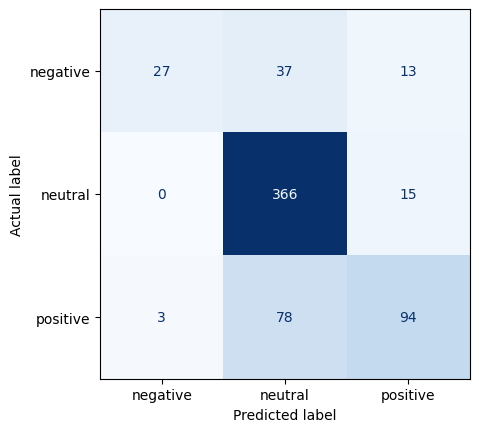

In [21]:
LABELS = ["negative", "neutral", "positive"]
disp = ConfusionMatrixDisplay.from_predictions(y_val, lr_pred, labels=LABELS, cmap="Blues", colorbar=False)
disp.ax_.set_xlabel("Predicted label")
disp.ax_.set_ylabel("Actual label")
plt.show()

The diagonal holds the correct predictions: 27 negative, 366 neutral and 94 positive sentences. The largest cell off the diagonal is **78** positive sentences predicted neutral.

**Precision** is the proportion of predictions of a label that are correct, and it is read down the label's column.

**Recall** is the proportion of the sentences with a label that are found, and it is read along the label's row.

**F1** combines precision and recall as 2 × precision × recall ÷ (precision + recall), which is high only when both are high.

The cell below computes precision and recall of every label from the cells of the matrix.

In [22]:
cm = confusion_matrix(y_val, lr_pred, labels=LABELS)
for i, label in enumerate(LABELS):
    precision = cm[i, i] / cm[:, i].sum()
    recall = cm[i, i] / cm[i, :].sum()
    print(f"{label:>8}: precision {cm[i, i]}/{cm[:, i].sum()} = {precision:.3f}, recall {cm[i, i]}/{cm[i, :].sum()} = {recall:.3f}")

negative: precision 27/30 = 0.900, recall 27/77 = 0.351
 neutral: precision 366/481 = 0.761, recall 366/381 = 0.961
positive: precision 94/122 = 0.770, recall 94/175 = 0.537


When logistic regression predicts negative it is right **27 times out of 30** (precision 0.900), but it finds only 27 of the 77 negative sentences (recall **0.351**).

The cell below prints the classification report, which gives the same precision and recall with F1, the support of each label, and two averages.

In [23]:
print(classification_report(y_val, lr_pred, labels=LABELS, digits=3))

              precision    recall  f1-score   support

    negative      0.900     0.351     0.505        77
     neutral      0.761     0.961     0.849       381
    positive      0.770     0.537     0.633       175

    accuracy                          0.769       633
   macro avg      0.810     0.616     0.662       633
weighted avg      0.780     0.769     0.748       633



The report's precision and recall match the calculation from the cells. The **macro average** of F1 is the plain mean of the three F1 scores, (0.505 + 0.849 + 0.633)/3 = **0.662**. The weighted average, 0.748, weights each label by its support, so it is dominated by neutral.

The cell below plots the F1 of each label for the three classifiers as grouped bars and prints the values.

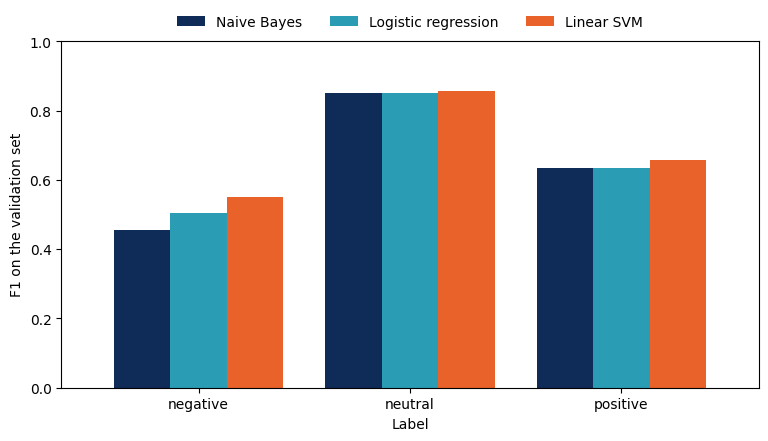

,Naive Bayes,Logistic regression,Linear SVM
negative,0.456,0.505,0.550
neutral,0.850,0.849,0.856
positive,0.634,0.633,0.658


In [24]:
f1_table = pd.DataFrame({name: f1_score(y_val, pred, labels=LABELS, average=None)
                         for name, pred in (("Naive Bayes", nb_pred), ("Logistic regression", lr_pred), ("Linear SVM", svm_pred))},
                        index=LABELS)
ax = f1_table.plot.bar(figsize=(9, 4.5), width=0.8, color=["#0F2B58", "#2A9DB5", "#E8622A"], rot=0)
ax.set_xlabel("Label")
ax.set_ylabel("F1 on the validation set")
ax.set_ylim(0, 1)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
plt.show()
f1_table.round(3)

The three classifiers differ most on **negative**, from 0.456 for Naive Bayes to **0.550** for the linear SVM. On neutral they are within 0.007 of each other, and the linear SVM has the highest F1 on every label.

## 9. Final Evaluation on the Test Set

Each classifier is evaluated once on the test set, after every choice has been made on the validation set. The result is reported with **macro F1** beside accuracy, because macro F1 gives the rare negative label the same weight as the frequent neutral one.

The cell below evaluates the four classifiers on the test set and saves the table to `comparison.csv`.

In [25]:
test_features = {"Majority baseline": C_test, "Naive Bayes": C_test,
                 "Logistic regression": X_test, "Linear SVM": X_test}
models = {"Majority baseline": baseline, "Naive Bayes": nb, "Logistic regression": lr, "Linear SVM": svm}
rows = []
for name, model in models.items():
    pred = model.predict(test_features[name])
    rows.append((name, round(accuracy_score(y_test, pred), 3), round(f1_score(y_test, pred, average="macro"), 3)))
comparison = pd.DataFrame(rows, columns=["classifier", "accuracy", "macro F1"])
comparison.to_csv("comparison.csv", index=False)
comparison

,classifier,accuracy,macro F1
0,Majority baseline,0.602,0.250
1,Naive Bayes,0.760,0.677
2,Logistic regression,0.766,0.667
3,Linear SVM,0.798,0.743


On the test set the baseline scores a macro F1 of **0.250**, Naive Bayes 0.677, logistic regression 0.667 and the linear SVM **0.743**. Macro F1 separates the classifiers more than accuracy does, because it counts the rare labels fully. Any later model measured on the same 633 test sentences adds one row to this table.

The cell below plots the test accuracy and the test macro F1 of each classifier side by side.

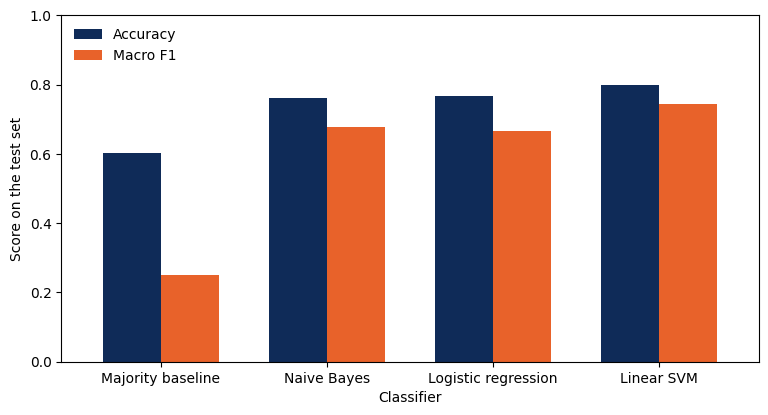

In [26]:
ax = comparison.set_index("classifier").plot.bar(figsize=(9, 4.5), width=0.7, color=["#0F2B58", "#E8622A"], rot=0)
ax.set_xlabel("Classifier")
ax.set_ylabel("Score on the test set")
ax.set_ylim(0, 1)
ax.legend(["Accuracy", "Macro F1"], loc="upper left", frameon=False)
plt.show()

The gap between the two bars is widest for the majority baseline, 0.602 against **0.250**, because its accuracy comes from the neutral sentences alone. Macro F1 also reverses the order of Naive Bayes and logistic regression, 0.677 against 0.667, which accuracy places the other way.

## Exercises

### Exercise 1: Comparing Macro and Weighted Averages

Print the **classification report** of the majority baseline on the validation set, with `zero_division=0`. In a Markdown cell, explain why its weighted average F1 is almost twice its macro average F1.

In [27]:
# TODO: Print the classification report of the majority baseline on the validation set.


**Expected result:** The baseline's F1 is 0 for negative and positive and **0.751** for neutral, so the macro average is about **0.25** and the weighted average about **0.45**. The weighted average follows the label proportions, so the 381 neutral sentences dominate it.

### Exercise 2: Evaluating the Linear SVM

Plot the **confusion matrix** of the linear SVM on the validation set with labeled axes. Then calculate from its cells the precision and recall of the label **positive**, and check them against the classification report.

In [28]:
# TODO: Plot the linear SVM confusion matrix, then compute the precision and recall of positive from its cells.


**Expected result:** The linear SVM labels **105** positive sentences correctly. Precision is 105/144 = **0.729** and recall 105/175 = **0.600**.

### Exercise 3: Analyzing Misclassified Sentences

Print the **3 positive sentences** that logistic regression predicts neutral with the highest probability, each with that probability. In a Markdown cell, describe what the three sentences have in common.

In [29]:
# TODO: Print the 3 positive sentences predicted neutral with the highest probability of neutral.


**Expected result:** The probabilities are about **0.92**, 0.92 and 0.91, for `The CHF is a great product .`, a sentence on combining and renewing a company's systems, and a sentence on Solidium's investment strategy. None contains a word of change such as `rose` or `increased`: the positive meaning comes from an opinion word or a plan.

### Exercise 4 (Extension): Evaluating Predictions Across Thresholds

Treat **negative** against the other two labels, using the logistic regression probability of negative on the validation set. Print the **AUC** of the ROC curve and the **average precision**. Then print the number of negative sentences found and the number of false positives at the thresholds 0.5, 0.3 and 0.1. Finally, plot the **ROC curve** and the **precision-recall curve** side by side, each with the line of a random ranking.

In [30]:
# TODO: Print the AUC, the average precision, and the counts at the thresholds 0.5, 0.3 and 0.1 for negative against the rest.


**Expected result:** The AUC is about **0.863** and the average precision about **0.611**, against 0.122 for a random ranking. At 0.5 the model finds 20 negative sentences with 2 false positives, and at 0.3 it finds 35 with 10. At 0.1 it finds **61**, at the cost of **120** false positives. The ROC curve rises steeply near the left edge, while the precision-recall curve falls as recall grows, which shows the false positives that the ROC curve hides on a rare label.